# Demo 3 — Classical structure as model input

**Question:** Does explicit frequency information help a flexible model generalize?

On hourly CISO electricity demand, we compare:

1. **Seasonal naive** — the baseline every comparison in this repo must clear.
2. **A small neural network on lagged observations only** — recent values
   (1, 2, 3, 24, 48, and 168 hours back), nothing else.
3. **The same network with Fourier terms added** — sine/cosine pairs encoding daily
   (24h) and weekly (168h) periodicity, alongside the same lags.
4. **SARIMAX with the same Fourier terms as exogenous regressors** — the classical
   benchmark, using seasonality the idiomatic SARIMAX way (as regressors at the
   *forecasted* time steps, rather than as descriptors of the input window).

This is not a reproduction of CoSPOT (Choi et al., 2026) — it's a small illustration of
its underlying principle: a flexible learner with no built-in notion of "day of week"
may generalize better once classical analysis hands it a credible representation of
recurring structure, rather than making it rediscover that structure from lags alone.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_electricity
from src.evaluation import rolling_origin_evaluate, summarize
from src.models import lag_regression_forecast, sarimax_fourier_forecast, seasonal_naive_forecast, select_order_by_aicc

warnings.filterwarnings("ignore")  # MLP/statsmodels convergence chatter; see Demos 1-2
RESULTS_DIR = "../results"


## Scale

As in the other demos, `SMALL_SCALE = True` keeps this fast (a handful of forecast
origins). Each origin here refits a small MLP twice and a SARIMAX model once on a
rolling window, so this is the most compute-bound notebook in the repo after Demo 1's
Chronos-2 calls — full scale mainly means more, and longer, refits.

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    LOOKBACK_HISTORY, TEST_SIZE, STEP = 6_000, 500, 60
else:
    LOOKBACK_HISTORY, TEST_SIZE, STEP = None, 1_500, 12

HORIZONS = {"short": 6, "medium": 24, "long": 168}
HORIZON_VALUES = sorted(HORIZONS.values())

LAGS = [1, 2, 3, 24, 48, 168]
FOURIER_PERIODS = [24, 168]
FOURIER_ORDER = 2
SEASON_LENGTH = 24
ROLLING_WINDOW = 24 * 90  # 90 days of history refit at every origin


In [3]:
ciso = load_electricity("CISO")
if LOOKBACK_HISTORY:
    ciso = ciso.iloc[-LOOKBACK_HISTORY:]

train = ciso.iloc[: len(ciso) - TEST_SIZE]
print(f"train={len(train)}  test={TEST_SIZE}  total={len(ciso)}")
print(f"train range: {train.index.min()} -> {train.index.max()}")

sarimax_order = select_order_by_aicc(train.iloc[-ROLLING_WINDOW:])
print("SARIMAX ARIMA order (chosen once on a training window, held fixed):", sarimax_order)


train=5500  test=500  total=6000
train range: 2025-12-11 01:00:00+00:00 -> 2026-07-28 04:00:00+00:00


SARIMAX ARIMA order (chosen once on a training window, held fixed): (2, 1, 2)


## Run all four models over the same test-period origins

In [4]:
seasonal_results = rolling_origin_evaluate(
    ciso, seasonal_naive_forecast, "Seasonal naive", HORIZON_VALUES,
    initial_train_size=len(train), step=STEP, model_kwargs={"season_length": SEASON_LENGTH},
)

lags_only_results = rolling_origin_evaluate(
    ciso, lag_regression_forecast, "MLP (lags only)", HORIZON_VALUES,
    initial_train_size=len(train), step=STEP, window="rolling", window_size=ROLLING_WINDOW,
    model_kwargs={"lags": LAGS},
)

lags_fourier_results = rolling_origin_evaluate(
    ciso, lag_regression_forecast, "MLP (lags + Fourier)", HORIZON_VALUES,
    initial_train_size=len(train), step=STEP, window="rolling", window_size=ROLLING_WINDOW,
    model_kwargs={"lags": LAGS, "fourier_periods": FOURIER_PERIODS, "fourier_order": FOURIER_ORDER},
)

sarimax_results = rolling_origin_evaluate(
    ciso, sarimax_fourier_forecast, "SARIMAX (Fourier)", HORIZON_VALUES,
    initial_train_size=len(train), step=STEP, window="rolling", window_size=ROLLING_WINDOW,
    model_kwargs={"fourier_periods": FOURIER_PERIODS, "fourier_order": FOURIER_ORDER, "order": sarimax_order},
)

all_results = pd.concat(
    [seasonal_results, lags_only_results, lags_fourier_results, sarimax_results], ignore_index=True,
)


In [5]:
summary = summarize(all_results)
summary["horizon_label"] = summary["horizon"].map({v: k for k, v in HORIZONS.items()})
summary = summary[["model", "horizon", "horizon_label", "n_forecasts", "mae", "rmse",
                     "mase", "directional_accuracy", "mean_elapsed_seconds"]]
summary


,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy,mean_elapsed_seconds
0,MLP (lags + Fourier),6,short,6,961.265649,1057.233071,0.975570,1.000000,1.128006
1,MLP (lags + Fourier),24,medium,6,1186.749326,1477.771801,1.193504,0.666667,1.128006
2,MLP (lags + Fourier),168,long,6,3704.463743,3938.584653,3.743693,0.500000,1.128006
3,MLP (lags only),6,short,6,759.406442,965.878732,0.762169,1.000000,2.059502
4,MLP (lags only),24,medium,6,1287.827411,1504.531422,1.294324,0.666667,2.059502
5,MLP (lags only),168,long,6,3502.084823,4000.676951,3.519891,0.500000,2.059502
6,SARIMAX (Fourier),6,short,6,1349.544940,1618.962058,1.371576,0.833333,1.216669
7,SARIMAX (Fourier),24,medium,6,1434.323403,1613.386243,1.449295,0.500000,1.216669
8,SARIMAX (Fourier),168,long,6,3296.190945,3486.856122,3.318751,0.500000,1.216669
9,Seasonal naive,6,short,6,887.000000,1242.399292,1.035729,0.833333,0.000091


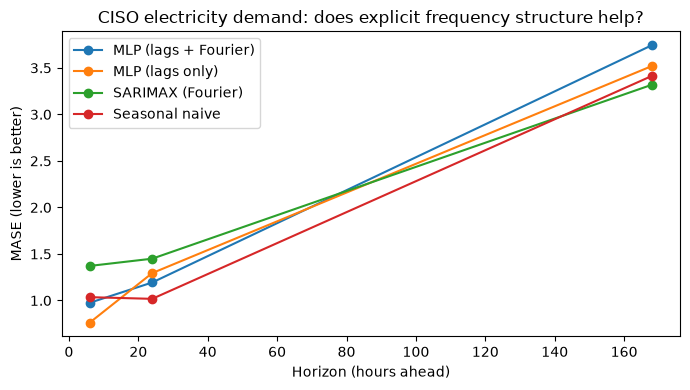

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for model, group in summary.groupby("model"):
    ax.plot(group["horizon"], group["mase"], marker="o", label=model)
ax.set_xlabel("Horizon (hours ahead)")
ax.set_ylabel("MASE (lower is better)")
ax.set_title("CISO electricity demand: does explicit frequency structure help?")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/demo3_ciso_mase_by_horizon.png", dpi=150)
plt.show()


In [7]:
summary.to_csv(f"{RESULTS_DIR}/metrics/demo3_ciso_summary.csv", index=False)
all_results.to_csv(f"{RESULTS_DIR}/metrics/demo3_ciso_test_forecasts.csv", index=False)


## One example, made concrete

Refit all three non-naive models once more at the final test-period origin and plot
their forecast paths against what actually happened, at the longest horizon.

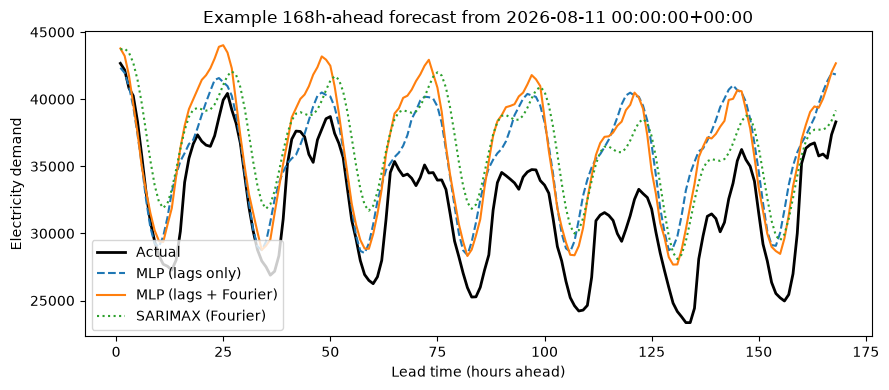

In [8]:
from src.models import build_lag_fourier_features_at

example_origin = len(ciso) - HORIZON_VALUES[-1]
window = ciso.iloc[example_origin - ROLLING_WINDOW: example_origin]

lags_only_path = lag_regression_forecast(window, horizon=HORIZON_VALUES[-1], lags=LAGS)["forecast"]
lags_fourier_path = lag_regression_forecast(
    window, horizon=HORIZON_VALUES[-1], lags=LAGS,
    fourier_periods=FOURIER_PERIODS, fourier_order=FOURIER_ORDER,
)["forecast"]
sarimax_path = sarimax_fourier_forecast(
    window, horizon=HORIZON_VALUES[-1],
    fourier_periods=FOURIER_PERIODS, fourier_order=FOURIER_ORDER, order=sarimax_order,
)["forecast"]
actual_path = ciso.iloc[example_origin: example_origin + HORIZON_VALUES[-1]].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
lead_times = np.arange(1, HORIZON_VALUES[-1] + 1)
ax.plot(lead_times, actual_path, label="Actual", color="black", linewidth=2)
ax.plot(lead_times, lags_only_path, label="MLP (lags only)", linestyle="--")
ax.plot(lead_times, lags_fourier_path, label="MLP (lags + Fourier)")
ax.plot(lead_times, sarimax_path, label="SARIMAX (Fourier)", linestyle=":")
ax.set_xlabel("Lead time (hours ahead)")
ax.set_ylabel("Electricity demand")
ax.set_title(f"Example {HORIZON_VALUES[-1]}h-ahead forecast from {ciso.index[example_origin - 1]}")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/demo3_ciso_example_forecast.png", dpi=150)
plt.show()


## Reading the results

- Compare MASE between "MLP (lags only)" and "MLP (lags + Fourier)" at each horizon —
  same architecture, same lags, the only difference is whether the model is handed an
  explicit encoding of daily/weekly phase. An improvement here is the demo's core claim;
  no improvement (or a regression) is also worth reporting honestly; small neural nets on
  small windows are not guaranteed to make good use of extra features.
- SARIMAX gives a classical reference point using the *same* Fourier terms, but attached
  to the forecasted time steps rather than the input window — a genuinely different way
  of using the same frequency information. Where it lands relative to both MLP variants
  says something about whether the value here is "frequency information" in general or
  the specific way a given model architecture consumes it.
- The lags list includes 24 and 168 directly, so "lags only" already has *some* access to
  daily/weekly structure — the comparison is about explicit, smooth phase encoding versus
  whatever a plain lag can capture, not about periodicity being entirely absent from one
  side.
- The single-example plot is illustrative, not a substitute for the aggregate MASE table —
  one 168-hour path can look better or worse than a model's typical behavior.
- Set `SMALL_SCALE = False` and rerun for the full-scale numbers used in the blog post.